# Deliverable 2 

The aim is to process a set of photographs to make them more amenable to Machine Learning algorithms. The processing to be carried out is a denoising operation. You will need to produce a Jupyter notebook explaining these pre-processing steps, and their performance. These algorithms will rely on convolutional auto-encoders, and apply them to improve image quality.

## 0. Setup

In [1]:
import os, glob, time, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
import cv2
from pathlib import Path
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim
from scipy.ndimage import median_filter, sobel
import tensorflow as tf
from tensorflow import keras
from keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, BatchNormalization , Concatenate, Dropout
from tensorflow.keras.models import Model
import pandas as pd

SEED = 123
rng = np.random.default_rng(SEED)
tf.keras.utils.set_random_seed(SEED)
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))
print("Devices: ", tf.config.list_physical_devices())


I0000 00:00:1792586400.537990    9109 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792586402.256326    9109 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Num GPUs Available:  1
Devices:  [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Main configuration
DATA_DIR = "dataset_deliverable2"
IMAGE_SIZE = 256
MAX_SIDE = 256
NOISE_FACTOR = 0.01
NB_EPOCHS_DENOISE = 50
BATCH_SIZE = 8
SAV_MODEL_DENOISE = "denoiser_photos.keras"


CACHE_DIR = "/mnt/ai/training_cache"          # Directory for caching dataset operations
#SAV_MODEL_DENOISE = "/" # Path to save the final model

## 1. Dataset

### 1.1 Loading and inspection

In [3]:
files = sorted(glob.glob(f"{DATA_DIR}/*.jpg"))
sizes = [Image.open(f).size for f in files]
w, h = np.array(sizes).T
print(f"{len(files)} images | width {w.min()}-{w.max()} px | height {h.min()}-{h.max()} px")
print("Distinct image sizes:", len(set(sizes)))

148 images | width 333-640 px | height 233-640 px
Distinct image sizes: 54


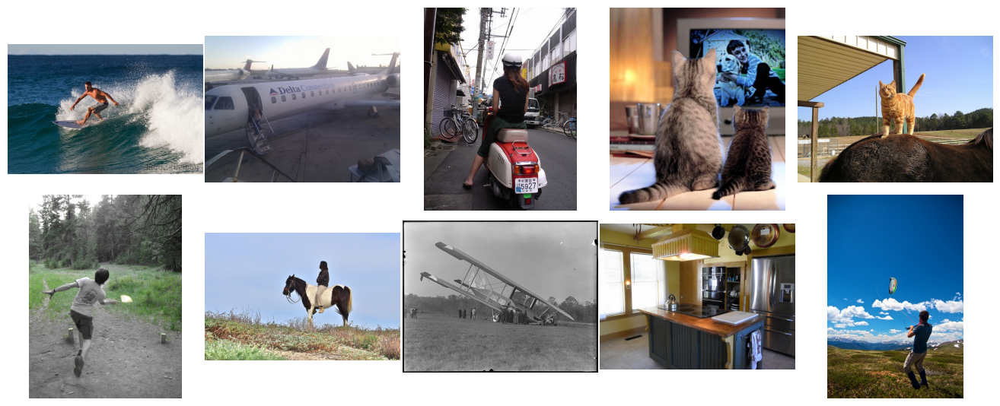

In [4]:
def display_image(X, n, grid_width=5):
    """Display the first n images of an array (N,H,W,C) or of a folder, as in the workshop."""
    if isinstance(X, (str, Path)):
        paths = sorted(Path(X).glob("*.jpg"))[:n]
        images = [np.asarray(Image.open(p).convert("RGB")) for p in paths]
    else:
        images = [np.asarray(X[i]).squeeze() for i in range(min(n, len(X)))]
    rows = (len(images) + grid_width - 1) // grid_width
    fig, axes = plt.subplots(rows, grid_width, figsize=(2.6 * grid_width, 2.6 * rows), squeeze=False)
    for ax in axes.flat: ax.axis("off")
    for ax, im in zip(axes.flat, images):
        ax.imshow(im, cmap="gray" if im.ndim == 2 else None)
    fig.tight_layout(pad=0.2); plt.show()

display_image(DATA_DIR, n=10)

The dataset contains diverse natural scenes (people, animals, vehicles, indoor/outdoor). It contains colour, textures, edges at many scales. Images are different sizes. So we need a pre-processing step to feed a fixed-size input to the network.

### 1.2 Pre-processing

1. Convert each photo to RGB and scale pixel values to **[0, 1]** (`/255.`).
2. Downscale each photo so its longest side is ≤ 256 px for later full-size evaluation.
3. Split data set (80 % train / 20 % test), so no photo appears in both sets.
4. For training, resize each full photo proportionally to fit **64×64**, then reflect-pad the shorter dimension. This produces one fixed-size sample per photo without cropping it into patches.

In [5]:
# 2.1 — Split by image (balanced by noise level), then cut 64x64 patches
from sklearn.model_selection import train_test_split

N_VAL, N_TEST = 15, 15
PATCHES_TRAIN = 60      # random patches per training image (~11,800 in total)
PATCHES_EVAL  = 30       # patches per validation image
EXTS  = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp")

paths  = sorted(os.path.join(DATA_DIR, f) for f in os.listdir(DATA_DIR) if f.lower().endswith(EXTS))
images = [np.asarray(Image.open(p).convert("RGB"), dtype=np.uint8) for p in paths]
names  = [os.path.basename(p) for p in paths]

meta = pd.DataFrame({"name": names,
                     "w": [im.shape[1] for im in images],
                     "h": [im.shape[0] for im in images]})
print(f"{len(images)} images loaded ({sum(im.nbytes for im in images) / 1e6:.0f} MB in memory)")
meta[["w", "h"]].describe().round(0)

148 images loaded (123 MB in memory)


,w,h
count,148.0,148.0
mean,584.0,479.0
std,86.0,95.0
min,333.0,233.0
25%,500.0,427.0
50%,640.0,480.0
75%,640.0,500.0
max,640.0,640.0


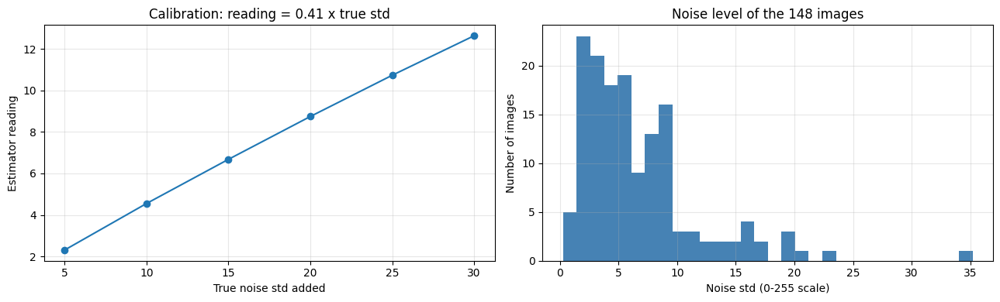

count    148.0
mean       6.7
std        5.1
min        0.3
25%        3.3
50%        5.4
75%        8.6
max       35.2
Name: sigma, dtype: float64

In [6]:
# 1.2 — Noise level of each image: measured on flat areas, then calibrated
def flat_residual(img, flat_quantile=0.3):
    """Residual (image - 3x3 median) on the flattest 30% of pixels: on flat areas, any variation is noise."""
    gray = img.astype(float).mean(axis=2)
    smooth = median_filter(gray, size=3)
    grad = np.hypot(sobel(smooth, 0), sobel(smooth, 1))
    flat = grad <= np.quantile(grad, flat_quantile)
    return (gray - smooth)[flat]

def noise_estimate(img):
    """Std of the flat-area residual, after dropping the 1% largest values (edges left over, isolated specks).
    A continuous measure: the median-based version was rounded to a few discrete values on 8-bit images."""
    r = flat_residual(img)
    r = r[np.abs(r) <= np.quantile(np.abs(r), 0.99)]
    return r.std()

meta["estimate"] = [noise_estimate(im) for im in images]

# Calibration: add Gaussian noise of KNOWN std to the 10 least noisy images and record the estimator's response
rng = np.random.default_rng(SEED)
cleanest = meta.sort_values("estimate").index[:10]
rows = []
for s_true in [5, 10, 15, 20, 25, 30]:
    for i in cleanest:
        noisy = np.clip(images[i] + rng.normal(0, s_true, images[i].shape), 0, 255)
        added = np.sqrt(max(noise_estimate(noisy) ** 2 - meta.estimate[i] ** 2, 0))  # variances add up
        rows.append((s_true, added))
calib = pd.DataFrame(rows, columns=["true_sigma", "estimate"]).groupby("true_sigma")["estimate"].mean()
k = np.polyfit(calib.index, calib.values, 1)[0]      # estimate ~ k x true sigma
meta["sigma"] = meta["estimate"] / k                  # equivalent Gaussian noise std (0-255 scale)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(calib.index, calib.values, "o-")
axes[0].set_xlabel("True noise std added")
axes[0].set_ylabel("Estimator reading")
axes[0].set_title(f"Calibration: reading = {k:.2f} x true std")
axes[1].hist(meta["sigma"], bins=30, color="steelblue")
axes[1].set_xlabel("Noise std (0-255 scale)")
axes[1].set_ylabel("Number of images")
axes[1].set_title("Noise level of the 148 images")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
meta["sigma"].describe().round(1)

In [7]:
PATCH = IMAGE_SIZE

meta["estimate"] = [noise_estimate(im) for im in images]
idx = np.arange(len(images))
noise_band = pd.qcut(meta["sigma"], 4, labels=False)                  # 4 bands of noise level
train_idx, test_idx = train_test_split(idx, test_size=N_TEST, stratify=noise_band, random_state=SEED)
train_idx, val_idx = train_test_split(train_idx, test_size=N_VAL, stratify=noise_band[train_idx], random_state=SEED)


print(f"Images -> train: {len(train_idx)} | val: {len(val_idx)} | test: {len(test_idx)}")

def random_patches(img_ids, n_per_image, rng):
    """Cut n random PATCH x PATCH crops from each image (uint8)."""
    out = []
    for i in img_ids:
        h, w, _ = images[i].shape
        for _ in range(n_per_image):
            y, x = rng.integers(0, h - PATCH + 1), rng.integers(0, w - PATCH + 1)
            out.append((images[i][y:y + PATCH, x:x + PATCH]/255.0)) #normalize by dividing by 255
    return np.stack(out)




rng = np.random.default_rng(SEED)
P_train = random_patches(train_idx, PATCHES_TRAIN, rng)

P_val   = random_patches(val_idx, PATCHES_EVAL, rng)

print(f"Patches -> train: {P_train.shape} | val: {P_val.shape}")

pd.DataFrame({"train": meta.sigma[train_idx].describe(), "val": meta.sigma[val_idx].describe(),
              "test": meta.sigma[test_idx].describe()}).round(1).loc[["mean", "50%", "min", "max"]]

Images -> train: 118 | val: 15 | test: 15
Patches -> train: (7080, 128, 128, 3) | val: (450, 128, 128, 3)


,train,val,test
mean,6.8,6.4,6.1
50%,5.4,5.6,4.7
min,0.3,0.4,1.9
max,35.2,15.0,16.0


In [8]:
"""def load_image(path, max_side=MAX_SIDE):
    im = Image.open(path).convert("RGB")
    im.thumbnail((max_side, max_side), Image.LANCZOS)
    return np.asarray(im, dtype="float32") / 255.

images = [load_image(f) for f in files]

perm = rng.permutation(len(images))
n_train = int(0.8 * len(images))

train_idx, test_idx = perm[:n_train], perm[n_train]
train_idx = P_train
test_idx = P_val
train_imgs = [images[i] for i in train_idx]
  = [images[i] for i in test_idx]
print(f"{len(train_imgs)} train images / {len()} test images")

def prepare_images(imgs, size=IMAGE_SIZE):
    out = []
    for image in imgs:
        height, width, _ = image.shape
        scale = min(size / height, size / width)
        new_height = max(1, round(height * scale))
        new_width = max(1, round(width * scale))
        resized = cv2.resize(image, (new_width, new_height), interpolation=cv2.INTER_AREA)
        top = (size - new_height) // 2
        bottom = size - new_height - top
        left = (size - new_width) // 2
        right = size - new_width - left
        out.append(cv2.copyMakeBorder(resized, top, bottom, left, right, cv2.BORDER_REFLECT_101))
    return np.stack(out).astype("float32")

x_train = prepare_images(train_imgs)
x_test = prepare_images()
print("x_train:", x_train.shape, " x_test:", x_test.shape, " range:", x_train.min(), "-", x_train.max())"""

'def load_image(path, max_side=MAX_SIDE):\n    im = Image.open(path).convert("RGB")\n    im.thumbnail((max_side, max_side), Image.LANCZOS)\n    return np.asarray(im, dtype="float32") / 255.\n\nimages = [load_image(f) for f in files]\n\nperm = rng.permutation(len(images))\nn_train = int(0.8 * len(images))\n\ntrain_idx, test_idx = perm[:n_train], perm[n_train]\ntrain_idx = P_train\ntest_idx = P_val\ntrain_imgs = [images[i] for i in train_idx]\n  = [images[i] for i in test_idx]\nprint(f"{len(train_imgs)} train images / {len()} test images")\n\ndef prepare_images(imgs, size=IMAGE_SIZE):\n    out = []\n    for image in imgs:\n        height, width, _ = image.shape\n        scale = min(size / height, size / width)\n        new_height = max(1, round(height * scale))\n        new_width = max(1, round(width * scale))\n        resized = cv2.resize(image, (new_width, new_height), interpolation=cv2.INTER_AREA)\n        top = (size - new_height) // 2\n        bottom = size - new_height - top\n     

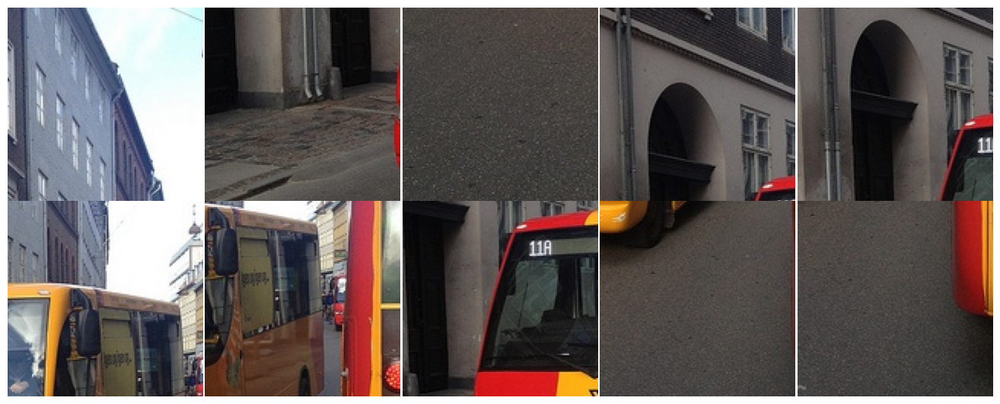

In [9]:
display_image(P_train, n=10)

## 2. Noise-reduction auto-encoder (denoiser)

**What are the input and output data of the auto-encoder?**

* **Input**: one full training photo, resized and padded to 64×64×3, with synthetic Gaussian noise added (`x_train_noisy`).
* **Output / target**: the same photo without synthetic noise (`x_train`).

Each source photo contributes one sample. Validation uses different held-out photos (`x_test_noisy`, `x_test`).

### 2.1 Generating the noise
Same recipe as the workshop: additive Gaussian noise with `noise_factor = 0.5` (i.e. a standard deviation of 0.25 on a [0,1] scale, which is a *strong* noise level), followed by clipping to [0, 1]. Because the dataset has no clean/noisy pairs, the images in the folder are treated as the targets.

P_train range: 0.0 - 1.0
Original :


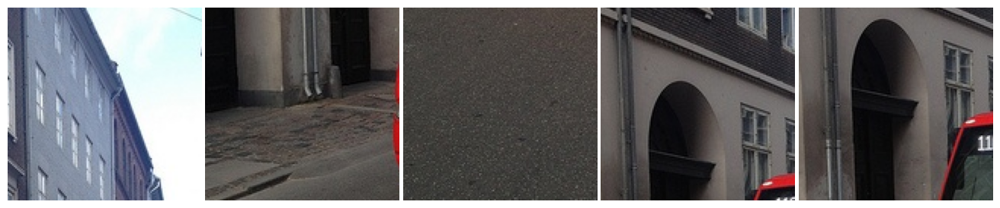

Noisy    :


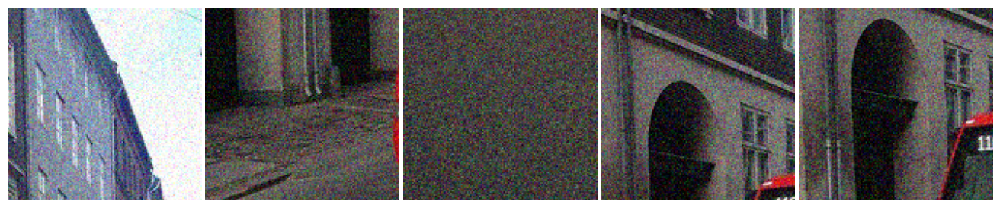

In [10]:
NOISE_FACTOR = 0.3
def add_noise(x, factor=NOISE_FACTOR, rng=rng):
    noisy = x + factor * rng.normal(loc=0.0, scale=factor, size=x.shape)

    
    return np.clip(noisy, 0.0, 1.0).astype("float32")

def add_noise(x, factor=NOISE_FACTOR, rng=rng):
         noisy = x + factor * rng.normal(loc=0.0, scale=factor, size=x.shape)
         #("Noisy range before clipping:", noisy.min(), "-", noisy.max())
         return np.clip(noisy, 0.0, 1.0).astype("float32")


x_train_noisy = add_noise(P_train)
print("P_train range:", P_train.min(), "-", P_train.max())
x_test_noisy  = add_noise(P_val)

print("Original :"); display_image(P_train, n=5)
print("Noisy    :"); display_image(x_train_noisy, n=5)

### 2.2 Architecture – encoder and decoder
The architecture is the workshop's one, adapted to RGB photos and 64×64 inputs:

* **Encoder**: 2 × (`Conv2D(32, 3×3, ReLU, same)` + `MaxPooling2D(2×2)`) → bottleneck of 16×16×32
* **Decoder**: the mirror: `Conv2D` + `UpSampling2D` ×2, then a final `Conv2D(3, sigmoid)` to output pixels in [0, 1] (consistent with `binary_crossentropy`).

The ReLU activation, the `same` padding, the `adam` optimiser and the `binary_crossentropy` loss are unchanged.

In [11]:
"""def build_autoencoder(input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)):
    input_img = Input(shape=input_shape)

    # Encoding
    x = Conv2D(32, (3, 3), activation="relu", padding="same")(input_img)
    x = MaxPooling2D((2, 2), padding="same")(x)
    x = Conv2D(32, (3, 3), activation="relu", padding="same")(x)
    encoded = MaxPooling2D((2, 2), padding="same")(x)

    # Decoding
    x = Conv2D(32, (3, 3), activation="relu", padding="same")(encoded)
    x = UpSampling2D((2, 2))(x)
    x = Conv2D(32, (3, 3), activation="relu", padding="same")(x)
    x = UpSampling2D((2, 2))(x)
    decoded = Conv2D(3, (3, 3), activation="sigmoid", padding="same")(x)

    model = Model(input_img, decoded)
    model.compile(optimizer="adam", loss="binary_crossentropy")
    return model

autoencoder = build_autoencoder()
autoencoder.summary()"""

'def build_autoencoder(input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)):\n    input_img = Input(shape=input_shape)\n\n    # Encoding\n    x = Conv2D(32, (3, 3), activation="relu", padding="same")(input_img)\n    x = MaxPooling2D((2, 2), padding="same")(x)\n    x = Conv2D(32, (3, 3), activation="relu", padding="same")(x)\n    encoded = MaxPooling2D((2, 2), padding="same")(x)\n\n    # Decoding\n    x = Conv2D(32, (3, 3), activation="relu", padding="same")(encoded)\n    x = UpSampling2D((2, 2))(x)\n    x = Conv2D(32, (3, 3), activation="relu", padding="same")(x)\n    x = UpSampling2D((2, 2))(x)\n    decoded = Conv2D(3, (3, 3), activation="sigmoid", padding="same")(x)\n\n    model = Model(input_img, decoded)\n    model.compile(optimizer="adam", loss="binary_crossentropy")\n    return model\n\nautoencoder = build_autoencoder()\nautoencoder.summary()'

In [12]:
def build_unet(input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)):
  input_img = Input(shape=input_shape)

  # --- ENCODER (Contractante) ---
  # Bloc 1
  c1 = Conv2D(64, (3, 3), activation="relu", padding="same")(input_img)
  c1 = BatchNormalization()(c1)
  c1 = Conv2D(64, (3, 3), activation="relu", padding="same")(c1)
  c1 = BatchNormalization()(c1)
  p1 = MaxPooling2D((2, 2), padding="same")(c1)
  p1 = Dropout(0.2)(p1)

  # Bloc 2
  c2 = Conv2D(128, (3, 3), activation="relu", padding="same")(p1)
  c2 = BatchNormalization()(c2)
  c2 = Conv2D(128, (3, 3), activation="relu", padding="same")(c2)
  c2 = BatchNormalization()(c2)
  p2 = MaxPooling2D((2, 2), padding="same")(c2)
  p2 = Dropout(0.2)(p2)

  # --- BRIDGE (Goulot d'étranglement) ---
  bridge = Conv2D(256, (3, 3), activation="relu", padding="same")(p2)
  bridge = BatchNormalization()(bridge)
  bridge = Conv2D(256, (3, 3), activation="relu", padding="same")(bridge)
  bridge = BatchNormalization()(bridge)
  bridge = Dropout(0.2)(bridge)

  # --- DECODER (expansive avec Skip Connections) ---
  # Bloc Décodage 1 (Concaténation avec c2)
  u1 = UpSampling2D((2, 2))(bridge)
  u1 = Concatenate()([u1, c2])
  u1 = Conv2D(128, (3, 3), activation="relu", padding="same")(u1)
  u1 = BatchNormalization()(u1)
  u1 = Conv2D(128, (3, 3), activation="relu", padding="same")(u1)
  u1 = BatchNormalization()(u1)
  u1 = Dropout(0.2)(u1)

  # Bloc Décodage 2 (Concaténation avec c1)
  u2 = UpSampling2D((2, 2))(u1)
  u2 = Concatenate()([u2, c1])
  u2 = Conv2D(64, (3, 3), activation="relu", padding="same")(u2)
  u2 = BatchNormalization()(u2)
  u2 = Conv2D(64, (3, 3), activation="relu", padding="same")(u2)
  u2 = BatchNormalization()(u2)
  u2 = Dropout(0.2)(u2)

  # --- SORTIE ---
  decoded = Conv2D(3, (3, 3), activation="sigmoid", padding="same")(u2)

  model = Model(input_img, decoded, name="U-Net_Autoencoder")
  model.compile(optimizer="adam", loss="binary_crossentropy")
  return model

# Instanciation et résumé
autoencoder_unet = build_unet()
autoencoder_unet.summary()

Model: "U-Net_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │      1,792 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │     36,928 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64, 64,    │          0 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     73,856 │ dropout[0][0]     │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │    147,584 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32, 32,    │          0 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │    295,168 │ dropout_1[0][0]   │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │      1,024 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │    590,080 │ batch_normalizat… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │      1,024 │ conv2d_5[0][0]  

 Total params: 1,889,923 (7.21 MB)

 Trainable params: 1,887,363 (7.20 MB)

 Non-trainable params: 2,560 (10.00 KB)

### 2.3 Training

In [13]:
t0 = time.time()


# Make sure data is float32
x_train_noisy = x_train_noisy.astype(np.float32)
P_train = P_train.astype(np.float32)

x_test_noisy = x_test_noisy.astype(np.float32)
P_val = P_val.astype(np.float32)


history = autoencoder_unet.fit(
    x_train_noisy, P_train,
    epochs=NB_EPOCHS_DENOISE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    validation_data=(x_test_noisy, P_val),
    verbose=2,
    
)
print(f"Training time: {(time.time() - t0)/60:.1f} min")

Epoch 1/50
885/885 - 141s - 159ms/step - loss: 0.5415 - val_loss: 1.1969
Epoch 2/50
885/885 - 47s - 53ms/step - loss: 0.5314 - val_loss: 0.7176
Epoch 3/50
885/885 - 48s - 55ms/step - loss: 0.5293 - val_loss: 0.5245
Epoch 4/50
885/885 - 49s - 56ms/step - loss: 0.5270 - val_loss: 0.5279
Epoch 5/50
885/885 - 50s - 56ms/step - loss: 0.5240 - val_loss: 0.5166
Epoch 6/50
885/885 - 50s - 56ms/step - loss: 0.5223 - val_loss: 0.5174
Epoch 7/50
885/885 - 50s - 56ms/step - loss: 0.5200 - val_loss: 0.5563
Epoch 8/50
885/885 - 50s - 56ms/step - loss: 0.5189 - val_loss: 0.6189
Epoch 9/50
885/885 - 50s - 56ms/step - loss: 0.5199 - val_loss: 0.5164
Epoch 10/50
885/885 - 50s - 56ms/step - loss: 0.5184 - val_loss: 0.5176
Epoch 11/50
885/885 - 50s - 56ms/step - loss: 0.5182 - val_loss: 0.5176
Epoch 12/50
885/885 - 50s - 56ms/step - loss: 0.5176 - val_loss: 0.5168
Epoch 13/50
885/885 - 50s - 56ms/step - loss: 0.5180 - val_loss: 0.5212
Epoch 14/50
885/885 - 51s - 58ms/step - loss: 0.5177 - val_loss: 0.5227

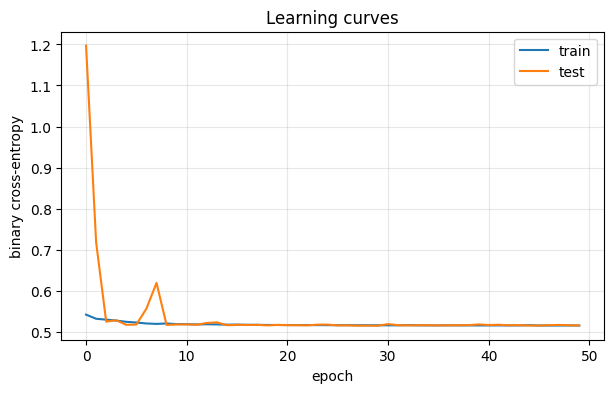

final train loss = 0.5149 | final val loss = 0.5153
best val loss = 0.5145 at epoch 30


In [14]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="test")
plt.xlabel("epoch"); plt.ylabel("binary cross-entropy"); plt.title("Learning curves"); plt.legend(); plt.grid(alpha=.3)
plt.show()

best = int(np.argmin(history.history["val_loss"]))
print(f"final train loss = {history.history['loss'][-1]:.4f} | final val loss = {history.history['val_loss'][-1]:.4f}")
print(f"best val loss = {history.history['val_loss'][best]:.4f} at epoch {best+1}")

## 3. Saving the model

In [16]:
autoencoder_unet.save(SAV_MODEL_DENOISE)
print(f"Model saved as {SAV_MODEL_DENOISE} ({os.path.getsize(SAV_MODEL_DENOISE)/1024:.0f} KB)")

Model saved as denoiser_photos.keras (22285 KB)


## 4. Evaluation on held-out images

### 4.1 Image-level predictions

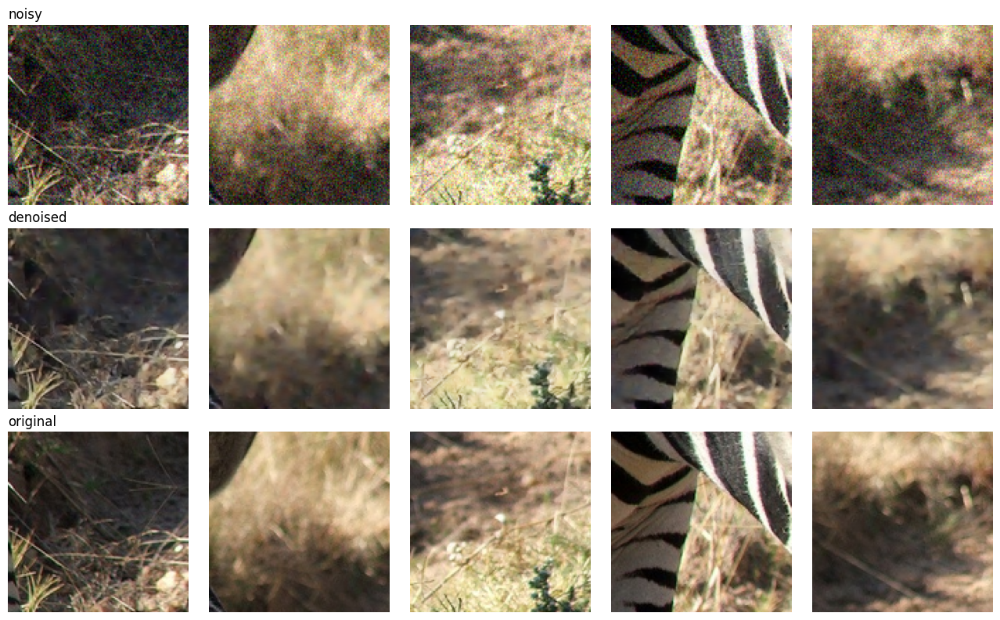

In [17]:
decoded_images = autoencoder_unet.predict(x_test_noisy, verbose=0)
idx = np.arange(0, 5) * 7
fig, axes = plt.subplots(3, 5, figsize=(13, 8))
for j, i in enumerate(idx):
    for r, (arr, t) in enumerate([(x_test_noisy, "noisy"), (decoded_images, "denoised"), (P_val, "original")]):
        axes[r, j].imshow(np.clip(arr[i], 0, 1)); axes[r, j].axis("off")
        if j == 0: axes[r, j].set_title(t, loc="left")
plt.tight_layout(); plt.show()

### 4.2 Full-size images
Since the network contains only convolution, pooling and up-sampling layers, it does not depend on the image size: we rebuild it with an input of shape `(None, None, 3)`, copy the trained weights, and run it on **entire** test images (cropped to a multiple of 4 so that pooling/up-sampling shapes match).

We compare it with three classical filters (the "convolution" approaches seen last year): Gaussian blur, median filter and Non-Local Means. Metrics: **PSNR** (dB, higher is better) and **SSIM** (0-1, higher is better), computed against the clean original.

In [18]:
fcn = build_unet(input_shape=(None, None, 3))
fcn.set_weights(autoencoder_unet.get_weights())

def crop4(a):
    H, W = a.shape[:2]
    return a[: H - H % 4, : W - W % 4]

def classical(noisy):
    u8 = (noisy * 255).astype("uint8")
    return {
        "Gaussian blur": cv2.GaussianBlur(u8, (0, 0), 1.5) / 255.,
        "Median 5x5":    cv2.medianBlur(u8, 5) / 255.,
        "Non-Local Means": cv2.fastNlMeansDenoisingColored(u8, None, 25, 25, 7, 21) / 255.,
    }

def evaluate(imgs, factor=NOISE_FACTOR, seed=0):
    r = np.random.default_rng(seed)
    res = {k: {"psnr": [], "ssim": []} for k in ["Noisy input", "Auto-encoder", "Gaussian blur", "Median 5x5", "Non-Local Means"]}
    for a in imgs:
        a = crop4(a)
        noisy = add_noise(a, factor, r)
        outs = {"Noisy input": noisy,
                "Auto-encoder": np.clip(fcn.predict(noisy[None], verbose=0)[0], 0, 1)}
        outs.update(classical(noisy))
        for k, o in outs.items():
            res[k]["psnr"].append(psnr(a, o, data_range=1.0))
            res[k]["ssim"].append(ssim(a, o, data_range=1.0, channel_axis=-1))
    return {k: (np.mean(v["psnr"]), np.mean(v["ssim"])) for k, v in res.items()}

t0 = time.time()
scores = evaluate(P_val)
print(f"{'Method':<18}{'PSNR (dB)':>10}{'SSIM':>8}")
for k, (p_, s_) in scores.items():
    print(f"{k:<18}{p_:>10.2f}{s_:>8.3f}")
print(f"({time.time()-t0:.0f}s)")

Method             PSNR (dB)    SSIM
Noisy input            21.33   0.380
Auto-encoder           29.70   0.842
Gaussian blur          27.06   0.707
Median 5x5             26.64   0.642
Non-Local Means        26.99   0.697
(62s)


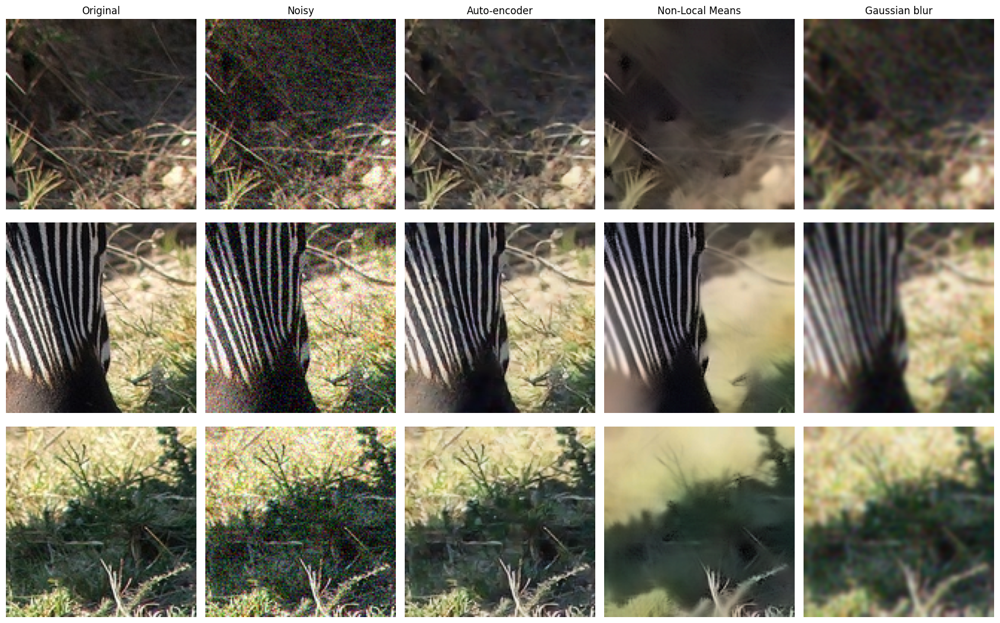

In [19]:
r = np.random.default_rng(123)
show = [P_val[i] for i in (0, 4, 9)]
fig, axes = plt.subplots(len(show), 5, figsize=(17, 3.6 * len(show)))
titles = ["Original", "Noisy", "Auto-encoder", "Non-Local Means", "Gaussian blur"]
for row, a in enumerate(show):
    a = crop4(a); noisy = add_noise(a, NOISE_FACTOR, r)
    den = np.clip(fcn.predict(noisy[None], verbose=0)[0], 0, 1)
    cl = classical(noisy)
    ims = [a, noisy, den, cl["Non-Local Means"], cl["Gaussian blur"]]
    for c, (im, t) in enumerate(zip(ims, titles)):
        axes[row, c].imshow(im); axes[row, c].axis("off")
        if row == 0: axes[row, c].set_title(t)
        if c >= 1: axes[row, c].set_xlabel(f"PSNR {psnr(a, im, data_range=1.0):.1f} dB")
plt.tight_layout(); plt.show()

### 4.3 Robustness to the noise level
The model was trained at a single noise level (`noise_factor = 0.5`). How does it behave on weaker/stronger noise?

noise_factor  noisy PSNR   AE PSNR  NLM PSNR
        0.20       28.08     28.56     22.28
        0.35       18.80     25.29     22.31
        0.50       13.42     18.48     18.21
        0.70        9.28     13.52     10.80


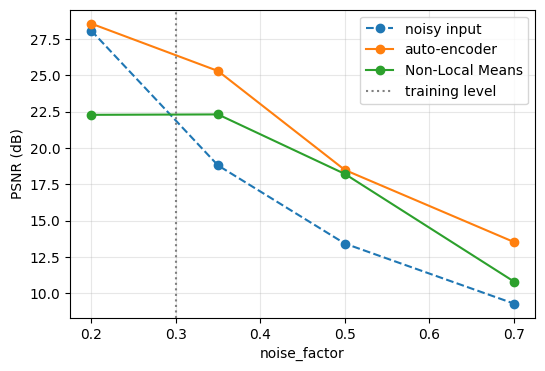

In [20]:
levels = [0.2, 0.35, 0.5, 0.7]
rows = []
for f in levels:
    s = evaluate(P_val[:15], factor=f)
    rows.append((f, s["Noisy input"][0], s["Auto-encoder"][0], s["Non-Local Means"][0]))
print(f"{'noise_factor':>12}{'noisy PSNR':>12}{'AE PSNR':>10}{'NLM PSNR':>10}")
for f, a, b, c in rows:
    print(f"{f:>12.2f}{a:>12.2f}{b:>10.2f}{c:>10.2f}")
plt.figure(figsize=(6, 4))
plt.plot(levels, [r_[1] for r_ in rows], "o--", label="noisy input")
plt.plot(levels, [r_[2] for r_ in rows], "o-", label="auto-encoder")
plt.plot(levels, [r_[3] for r_ in rows], "o-", label="Non-Local Means")
plt.axvline(NOISE_FACTOR, color="grey", ls=":", label="training level")
plt.xlabel("noise_factor"); plt.ylabel("PSNR (dB)"); plt.legend(); plt.grid(alpha=.3); plt.show()

## 5. Applying the model to the dataset images *as they are*

Finally, the images in `Dataset/` are labelled "noisy". Here we feed them **without adding any synthetic noise** and look at what the model does to them. There is no ground truth, so this is a purely qualitative check (and a sanity test of what the network has learned).

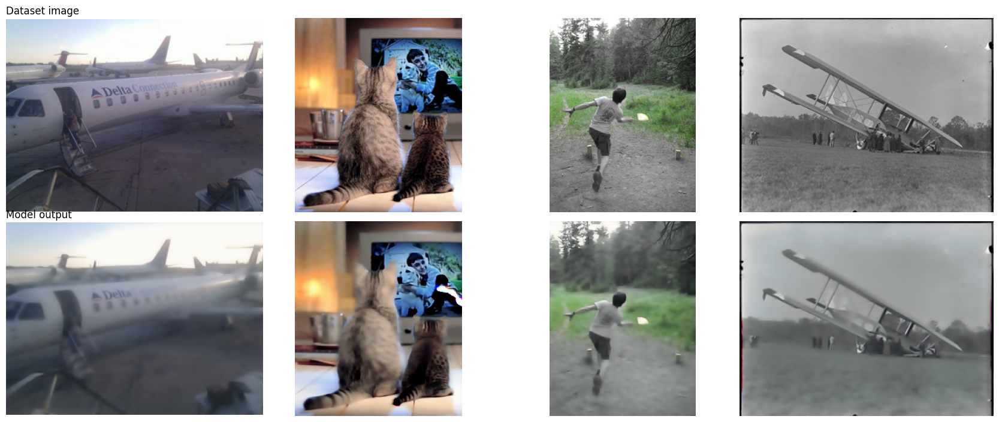

In [21]:
def load_image(path, max_side=MAX_SIDE):
    im = Image.open(path).convert("RGB")
    im.thumbnail((max_side, max_side), Image.LANCZOS)
    return np.asarray(im, dtype="float32") / 255.


sel = [1, 3, 5, 7]   # indices of images in the folder
fig, axes = plt.subplots(2, len(sel), figsize=(4.2 * len(sel), 7))
for c, i in enumerate(sel):
    a = crop4(load_image(files[i]))
    den = np.clip(fcn.predict(a[None], verbose=0)[0], 0, 1)
    axes[0, c].imshow(a); axes[0, c].axis("off"); axes[1, c].imshow(den); axes[1, c].axis("off")
    # estimate of the high-frequency energy removed (std of the difference)
    axes[1, c].set_xlabel(f"mean |change| = {np.abs(a-den).mean()*255:.1f} / 255")
axes[0, 0].set_title("Dataset image", loc="left"); axes[1, 0].set_title("Model output", loc="left")
plt.tight_layout(); plt.show()

## 6. Conclusion

**Summary.** The model is trained on one resized 64×64 sample from each of 118 training photos and validated on 50 separate photos. The full images are retained for full-size evaluation.

**Important.** The numerical results and conclusions below reflect the previous patch-based run. Rerun training and evaluation after changing the preprocessing before using those figures as results for this one-image-per-sample setup.

1. **Denoising quality.** Compare the regenerated PSNR/SSIM results at `noise_factor = 0.5` against the classical filters in section 4.2.
2. **Detail preservation.** Inspect the visual comparisons to see how well edges and textures are retained.
3. **Noise-level generalisation.** Section 4.3 evaluates weaker and stronger noise levels. The model is trained at `noise_factor = 0.5`, corresponding to a noise standard deviation of 0.25 on the [0,1] scale.
4. **Real dataset images.** The images are used without added noise in section 5. There is no clean ground truth, so this is a qualitative check only.

**Possible next steps.** Train longer with fresh noise at each epoch and several noise levels (blind denoising); add skip connections (U-Net / residual learning) to preserve detail; use an MSE or perceptual/SSIM loss instead of binary cross-entropy; and obtain real paired data (or use Noise2Noise-style training) to denoise the actual photographs.

**Files.** `Deliverable_2_Denoising_Autoencoder.ipynb` (this notebook) and `denoiser_photos.keras` (weights from the previous patch-based run; rerun training and the save cell to regenerate them). To re-run, place the notebook next to the `Dataset/` folder.